In [1]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

AOD_DIR = PROJECT_DIR / "data" / "raw" / "AOD"
LST_DIR = PROJECT_DIR / "data" / "raw" / "LST"
DATA_DIR = PROJECT_DIR / "data" / "processed"

aod_file = AOD_DIR / "3DIMG_18JUN2024_0530_L2G_AOD_V02R00.h5"
lst_file = LST_DIR / "3DIMG_18JUN2024_0530_L2B_LST_V01R00.h5"

In [2]:
with h5py.File(aod_file, "r") as f:
    aod = f["AOD"][0]
    aod_lat = f["latitude"][:]
    aod_lon = f["longitude"][:]

# Replace missing AOD
aod = np.where(aod == -999, np.nan, aod)

In [3]:
with h5py.File(lst_file, "r") as f:
    lst = f["LST"][0]

    lat_raw = f["Latitude"][:]
    lon_raw = f["Longitude"][:]

    # Apply scale factor 0.01
    lst_lat = lat_raw.astype(float) * 0.01
    lst_lon = lon_raw.astype(float) * 0.01


# -----------------------------
# 3. Select valid LST pixels
# -----------------------------
valid_lst = (
    (lat_raw != 32767) &
    (lon_raw != 32767) &
    (lst != -999)
)

lst_lat_valid = lst_lat[valid_lst]
lst_lon_valid = lst_lon[valid_lst]
lst_value_valid = lst[valid_lst]


print("Valid LST observations:", len(lst_value_valid))

Valid LST observations: 445473


In [4]:
region_mask = (
    (lst_lat_valid >= aod_lat.min()) &
    (lst_lat_valid <= aod_lat.max()) &
    (lst_lon_valid >= aod_lon.min()) &
    (lst_lon_valid <= aod_lon.max())
)

lst_lat_region = lst_lat_valid[region_mask]
lst_lon_region = lst_lon_valid[region_mask]
lst_value_region = lst_value_valid[region_mask]

print("LST observations inside AOD region:", len(lst_value_region))

LST observations inside AOD region: 224919


In [5]:
def latlon_to_xyz(lat, lon):
    lat = np.radians(lat)
    lon = np.radians(lon)

    x = np.cos(lat) * np.cos(lon)
    y = np.cos(lat) * np.sin(lon)
    z = np.sin(lat)

    return np.column_stack((x, y, z))


lst_xyz = latlon_to_xyz(
    lst_lat_region,
    lst_lon_region
)

tree = cKDTree(lst_xyz)

print("KD-tree created.")

KD-tree created.


In [6]:
valid_aod_positions = np.argwhere(~np.isnan(aod))

sample_positions = valid_aod_positions[:10]

sample_lat = aod_lat[sample_positions[:, 0]]
sample_lon = aod_lon[sample_positions[:, 1]]
sample_aod = aod[
    sample_positions[:, 0],
    sample_positions[:, 1]
]

print("Sample AOD observations:")
for lat, lon, value in zip(sample_lat, sample_lon, sample_aod):
    print(
        f"Lat={lat:.2f}, "
        f"Lon={lon:.2f}, "
        f"AOD={value:.4f}"
    )

Sample AOD observations:
Lat=45.05, Lon=49.75, AOD=0.2335
Lat=45.05, Lon=50.05, AOD=0.1111
Lat=45.05, Lon=58.55, AOD=0.2187
Lat=45.05, Lon=73.05, AOD=0.9491
Lat=45.05, Lon=75.45, AOD=1.1891
Lat=45.05, Lon=75.55, AOD=1.1891
Lat=45.05, Lon=78.45, AOD=1.0773
Lat=45.05, Lon=82.95, AOD=0.9633
Lat=45.05, Lon=83.05, AOD=1.1003
Lat=45.05, Lon=83.35, AOD=2.0582


In [7]:
sample_xyz = latlon_to_xyz(
    sample_lat,
    sample_lon
)

distances, indices = tree.query(sample_xyz)

nearest_lst_lat = lst_lat_region[indices]
nearest_lst_lon = lst_lon_region[indices]
nearest_lst_value = lst_value_region[indices]

print("\nNearest LST observations:")

for i in range(len(sample_lat)):
    print(
        f"AOD: "
        f"({sample_lat[i]:.2f}, {sample_lon[i]:.2f}) "
        f"→ "
        f"LST: "
        f"({nearest_lst_lat[i]:.2f}, {nearest_lst_lon[i]:.2f}) "
        f"| LST={nearest_lst_value[i]:.2f} K"
    )


Nearest LST observations:
AOD: (45.05, 49.75) → LST: (44.39, 50.48) | LST=322.06 K
AOD: (45.05, 50.05) → LST: (44.39, 50.48) | LST=322.06 K
AOD: (45.05, 58.55) → LST: (45.01, 58.53) | LST=313.25 K
AOD: (45.05, 73.05) → LST: (44.79, 72.73) | LST=327.96 K
AOD: (45.05, 75.45) → LST: (44.67, 75.44) | LST=336.71 K
AOD: (45.05, 75.55) → LST: (44.67, 75.60) | LST=329.79 K
AOD: (45.05, 78.45) → LST: (44.63, 78.59) | LST=317.48 K
AOD: (45.05, 82.95) → LST: (44.86, 82.96) | LST=327.10 K
AOD: (45.05, 83.05) → LST: (44.86, 83.06) | LST=325.25 K
AOD: (45.05, 83.35) → LST: (44.86, 83.06) | LST=325.25 K


In [8]:
# Convert chord distance on unit sphere to kilometres

EARTH_RADIUS_KM = 6371.0

chord_distance = distances

angular_distance = 2 * np.arcsin(
    np.clip(chord_distance / 2, 0, 1)
)

distance_km = EARTH_RADIUS_KM * angular_distance


print("Nearest-neighbour distances:")
print("Minimum:", distance_km.min(), "km")
print("Maximum:", distance_km.max(), "km")
print("Mean:", distance_km.mean(), "km")
print("Median:", np.median(distance_km), "km")

print("\nIndividual distances:")

for i in range(len(sample_lat)):
    print(
        f"AOD ({sample_lat[i]:.2f}, {sample_lon[i]:.2f}) "
        f"→ LST ({nearest_lst_lat[i]:.2f}, {nearest_lst_lon[i]:.2f}) "
        f"= {distance_km[i]:.2f} km"
    )

Nearest-neighbour distances:
Minimum: 4.717326689052342 km
Maximum: 93.34022113743609 km
Mean: 42.33462322222434 km
Median: 40.30519227472365 km

Individual distances:
AOD (45.05, 49.75) → LST (44.39, 50.48) = 93.34 km
AOD (45.05, 50.05) → LST (44.39, 50.48) = 80.87 km
AOD (45.05, 58.55) → LST (45.01, 58.53) = 4.72 km
AOD (45.05, 73.05) → LST (44.79, 72.73) = 38.35 km
AOD (45.05, 75.45) → LST (44.67, 75.44) = 42.26 km
AOD (45.05, 75.55) → LST (44.67, 75.60) = 42.44 km
AOD (45.05, 78.45) → LST (44.63, 78.59) = 47.99 km
AOD (45.05, 82.95) → LST (44.86, 82.96) = 21.14 km
AOD (45.05, 83.05) → LST (44.86, 83.06) = 21.14 km
AOD (45.05, 83.35) → LST (44.86, 83.06) = 31.10 km


In [9]:
print("\nDistance percentiles:")

for p in [25, 50, 75, 90, 95, 99]:
    print(
        f"{p}th percentile:",
        np.percentile(distance_km, p),
        "km"
    )


Distance percentiles:
25th percentile: 23.630761945743956 km
50th percentile: 40.30519227472365 km
75th percentile: 46.60084147699969 km
90th percentile: 82.11778454519862 km
95th percentile: 87.72900284131734 km
99th percentile: 92.21797747821235 km


In [ ]:
# Pick one AOD grid cell
i = 200
j = 200

center_lat = aod_lat[i]
center_lon = aod_lon[j]

# Assuming temporarily that coordinates are cell centres
lat_min = center_lat - 0.05
lat_max = center_lat + 0.05

lon_min = center_lon - 0.05
lon_max = center_lon + 0.05

print("AOD coordinate:")
print("Latitude:", center_lat)
print("Longitude:", center_lon)

print("\nTemporary cell boundaries:")
print("Latitude:", lat_min, "to", lat_max)
print("Longitude:", lon_min, "to", lon_max)

AOD coordinate:
Latitude: 25.049999999999997
Longitude: 65.05

Temporary cell boundaries:
Latitude: 24.999999999999996 to 25.099999999999998
Longitude: 65.0 to 65.1


In [11]:
cell_mask = (
    (lst_lat_region >= lat_min) &
    (lst_lat_region < lat_max) &
    (lst_lon_region >= lon_min) &
    (lst_lon_region < lon_max)
)

cell_lst = lst_value_region[cell_mask]

print("Number of valid LST pixels:", len(cell_lst))

if len(cell_lst) > 0:
    print("Mean LST:", np.mean(cell_lst), "K")
    print("Median LST:", np.median(cell_lst), "K")
    print("Minimum LST:", np.min(cell_lst), "K")
    print("Maximum LST:", np.max(cell_lst), "K")

Number of valid LST pixels: 0


In [12]:
print("AOD cell:")
print("Lat:", center_lat)
print("Lon:", center_lon)

print("\nLST points near this location:")

nearby = (
    (np.abs(lst_lat_region - center_lat) <= 0.5) &
    (np.abs(lst_lon_region - center_lon) <= 0.5)
)

nearby_lat = lst_lat_region[nearby]
nearby_lon = lst_lon_region[nearby]
nearby_lst = lst_value_region[nearby]

print("Number within ±0.5°:", len(nearby_lst))

for k in range(min(20, len(nearby_lst))):
    print(
        f"Lat={nearby_lat[k]:.2f}, "
        f"Lon={nearby_lon[k]:.2f}, "
        f"LST={nearby_lst[k]:.2f} K"
    )

AOD cell:
Lat: 25.049999999999997
Lon: 65.05

LST points near this location:
Number within ±0.5°: 6
Lat=25.34, Lon=64.80, LST=321.55 K
Lat=25.34, Lon=64.85, LST=322.69 K
Lat=25.33, Lon=64.89, LST=320.42 K
Lat=25.33, Lon=64.93, LST=318.61 K
Lat=25.33, Lon=64.98, LST=319.84 K
Lat=25.17, Lon=64.61, LST=312.41 K


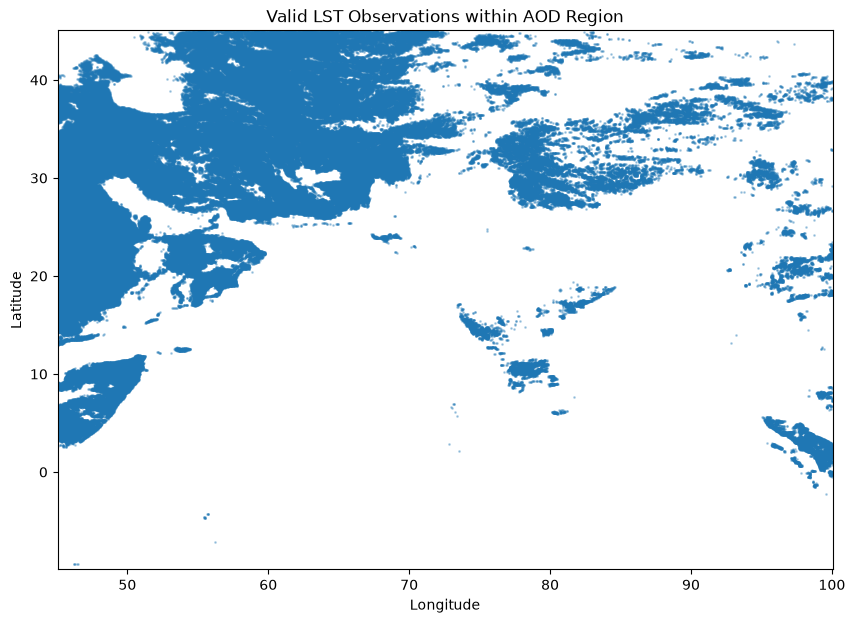

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    lst_lon_region,
    lst_lat_region,
    s=1,
    alpha=0.3
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Valid LST Observations within AOD Region")

plt.xlim(aod_lon.min(), aod_lon.max())
plt.ylim(aod_lat.min(), aod_lat.max())

plt.show()

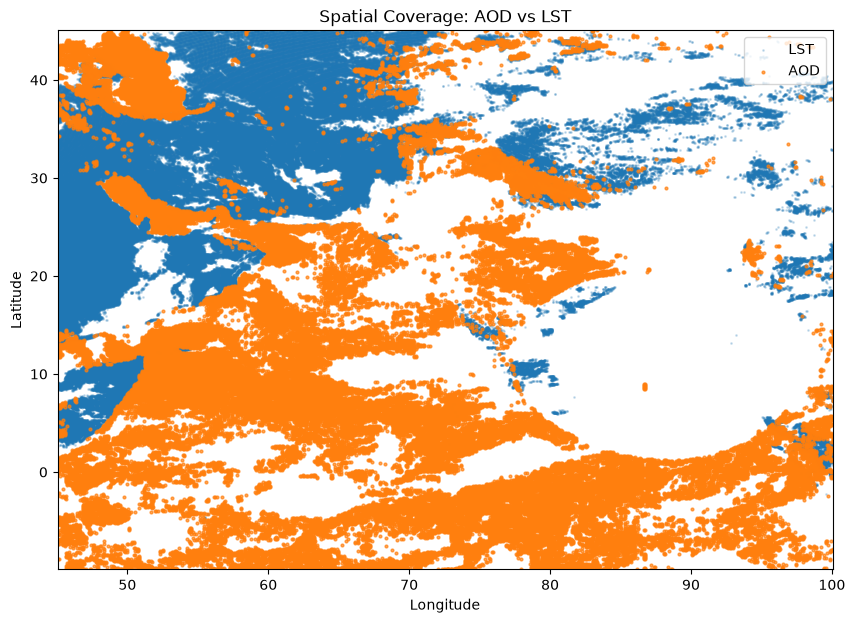

In [14]:
valid_aod_positions = np.argwhere(~np.isnan(aod))

aod_valid_lat = aod_lat[valid_aod_positions[:, 0]]
aod_valid_lon = aod_lon[valid_aod_positions[:, 1]]

plt.figure(figsize=(10, 7))

# LST
plt.scatter(
    lst_lon_region,
    lst_lat_region,
    s=1,
    alpha=0.2,
    label="LST"
)

# AOD
plt.scatter(
    aod_valid_lon,
    aod_valid_lat,
    s=4,
    alpha=0.7,
    label="AOD"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Coverage: AOD vs LST")

plt.xlim(aod_lon.min(), aod_lon.max())
plt.ylim(aod_lat.min(), aod_lat.max())

plt.legend()
plt.show()

In [15]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Get valid AOD coordinates and values
# --------------------------------------------------

valid_aod_positions = np.argwhere(~np.isnan(aod))

aod_lat_valid = aod_lat[valid_aod_positions[:, 0]]
aod_lon_valid = aod_lon[valid_aod_positions[:, 1]]
aod_value_valid = aod[
    valid_aod_positions[:, 0],
    valid_aod_positions[:, 1]
]

print("Valid AOD observations:", len(aod_value_valid))
print("Valid LST observations:", len(lst_value_region))


# --------------------------------------------------
# 2. Function to test a common grid
# --------------------------------------------------

def test_common_grid(grid_size):

    # AOD grid-cell IDs
    aod_cell_lat = np.floor(aod_lat_valid / grid_size).astype(int)
    aod_cell_lon = np.floor(aod_lon_valid / grid_size).astype(int)

    aod_cells = set(
        zip(aod_cell_lat, aod_cell_lon)
    )

    # LST grid-cell IDs
    lst_cell_lat = np.floor(lst_lat_region / grid_size).astype(int)
    lst_cell_lon = np.floor(lst_lon_region / grid_size).astype(int)

    lst_cells = set(
        zip(lst_cell_lat, lst_cell_lon)
    )

    # Cells containing both datasets
    common_cells = aod_cells.intersection(lst_cells)

    return {
        "grid_size": grid_size,
        "AOD_cells": len(aod_cells),
        "LST_cells": len(lst_cells),
        "Common_cells": len(common_cells),
        "AOD_coverage_%": 100 * len(common_cells) / len(aod_cells),
        "LST_coverage_%": 100 * len(common_cells) / len(lst_cells)
    }


# --------------------------------------------------
# 3. Test three grid sizes
# --------------------------------------------------

results = []

for size in [0.25, 0.50, 1.00]:
    results.append(test_common_grid(size))

results_df = pd.DataFrame(results)

print(results_df)

Valid AOD observations: 69272
Valid LST observations: 224919
   grid_size  AOD_cells  LST_cells  Common_cells  AOD_coverage_%  \
0       0.25      16036      12715          1940       12.097780   
1       0.50       5336       3877          1028       19.265367   
2       1.00       1720       1201           507       29.476744   

   LST_coverage_%  
0       15.257570  
1       26.515347  
2       42.214821  


In [16]:
# ---------------------------------------------
# Create 1-degree common spatial cells
# ---------------------------------------------

grid_size = 1.0

# AOD cell IDs
aod_cell_lat = np.floor(aod_lat_valid / grid_size).astype(int)
aod_cell_lon = np.floor(aod_lon_valid / grid_size).astype(int)

aod_df = pd.DataFrame({
    "cell_lat": aod_cell_lat,
    "cell_lon": aod_cell_lon,
    "AOD": aod_value_valid
})

# Count AOD observations per cell
aod_counts = (
    aod_df
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="AOD_count")
)


# LST cell IDs
lst_cell_lat = np.floor(
    lst_lat_region / grid_size
).astype(int)

lst_cell_lon = np.floor(
    lst_lon_region / grid_size
).astype(int)

lst_df = pd.DataFrame({
    "cell_lat": lst_cell_lat,
    "cell_lon": lst_cell_lon,
    "LST": lst_value_region
})

# Count LST observations per cell
lst_counts = (
    lst_df
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="LST_count")
)


# Combine counts
cell_counts = pd.merge(
    aod_counts,
    lst_counts,
    on=["cell_lat", "cell_lon"],
    how="inner"
)

print("Number of common cells:", len(cell_counts))

print("\nFirst 20 common cells:")
print(cell_counts.head(20))

Number of common cells: 507

First 20 common cells:
    cell_lat  cell_lon  AOD_count  LST_count
0        -10        46         84          5
1         -8        56         68          1
2         -5        55         18         11
3         -3        99          1          1
4         -2        98         55         31
5         -1        97         99          1
6         -1        98         73         39
7         -1        99         36         53
8         -1       100          4         10
9          0        97         92         66
10         0        98         69         27
11         0        99         45        310
12         0       100          1          8
13         1        97         50         64
14         1        98         76        184
15         1        99         31        514
16         2        46         37          8
17         2        72         83          1
18         2        73         95          1
19         2        95         49         57


In [17]:
print("\nAOD observations per common cell:")
print(cell_counts["AOD_count"].describe())

print("\nLST observations per common cell:")
print(cell_counts["LST_count"].describe())


AOD observations per common cell:
count    507.000000
mean      24.919132
std       28.574557
min        1.000000
25%        3.000000
50%       11.000000
75%       39.000000
max      100.000000
Name: AOD_count, dtype: float64

LST observations per common cell:
count    507.000000
mean     160.311637
std      143.617347
min        1.000000
25%       27.000000
50%      120.000000
75%      280.000000
max      582.000000
Name: LST_count, dtype: float64


In [18]:
print("\nCommon cells with different minimum LST counts:")

for threshold in [1, 5, 10, 20, 50, 100]:
    
    count = (
        cell_counts["LST_count"] >= threshold
    ).sum()
    
    print(
        f"LST count >= {threshold}: "
        f"{count} cells"
    )


Common cells with different minimum LST counts:
LST count >= 1: 507 cells
LST count >= 5: 467 cells
LST count >= 10: 425 cells
LST count >= 20: 393 cells
LST count >= 50: 345 cells
LST count >= 100: 268 cells


In [19]:
# Test different minimum observation requirements

print("Minimum observation thresholds\n")

for aod_threshold in [1, 5, 10, 20, 30, 50]:
    
    for lst_threshold in [10, 20, 50, 100]:
        
        selected = cell_counts[
            (cell_counts["AOD_count"] >= aod_threshold) &
            (cell_counts["LST_count"] >= lst_threshold)
        ]
        
        print(
            f"AOD >= {aod_threshold:3d}, "
            f"LST >= {lst_threshold:3d} "
            f"→ {len(selected):3d} cells"
        )
    
    print()

Minimum observation thresholds

AOD >=   1, LST >=  10 → 425 cells
AOD >=   1, LST >=  20 → 393 cells
AOD >=   1, LST >=  50 → 345 cells
AOD >=   1, LST >= 100 → 268 cells

AOD >=   5, LST >=  10 → 286 cells
AOD >=   5, LST >=  20 → 268 cells
AOD >=   5, LST >=  50 → 236 cells
AOD >=   5, LST >= 100 → 183 cells

AOD >=  10, LST >=  10 → 231 cells
AOD >=  10, LST >=  20 → 218 cells
AOD >=  10, LST >=  50 → 191 cells
AOD >=  10, LST >= 100 → 146 cells

AOD >=  20, LST >=  10 → 164 cells
AOD >=  20, LST >=  20 → 155 cells
AOD >=  20, LST >=  50 → 137 cells
AOD >=  20, LST >= 100 →  99 cells

AOD >=  30, LST >=  10 → 133 cells
AOD >=  30, LST >=  20 → 125 cells
AOD >=  30, LST >=  50 → 111 cells
AOD >=  30, LST >= 100 →  81 cells

AOD >=  50, LST >=  10 →  77 cells
AOD >=  50, LST >=  20 →  71 cells
AOD >=  50, LST >=  50 →  61 cells
AOD >=  50, LST >= 100 →  40 cells



In [20]:
# Total valid AOD observations
total_aod = len(aod_value_valid)

print("Total valid AOD observations:", total_aod)
print()

for threshold in [1, 5, 10, 20, 30, 50]:
    
    selected_cells = cell_counts[
        cell_counts["AOD_count"] >= threshold
    ]
    
    retained_aod = selected_cells["AOD_count"].sum()
    
    percentage = (
        retained_aod / total_aod
    ) * 100
    
    print(
        f"AOD >= {threshold:2d} per cell → "
        f"{len(selected_cells):3d} cells | "
        f"{retained_aod:5d} AOD observations | "
        f"{percentage:.2f}% of valid AOD"
    )

Total valid AOD observations: 69272

AOD >=  1 per cell → 507 cells | 12634 AOD observations | 18.24% of valid AOD
AOD >=  5 per cell → 334 cells | 12274 AOD observations | 17.72% of valid AOD
AOD >= 10 per cell → 268 cells | 11836 AOD observations | 17.09% of valid AOD
AOD >= 20 per cell → 196 cells | 10792 AOD observations | 15.58% of valid AOD
AOD >= 30 per cell → 162 cells |  9967 AOD observations | 14.39% of valid AOD
AOD >= 50 per cell →  99 cells |  7492 AOD observations | 10.82% of valid AOD


In [21]:
# ---------------------------------------------
# 0.5-degree common grid
# ---------------------------------------------

grid_size = 0.5

# AOD cells
aod_cell_lat = np.floor(
    aod_lat_valid / grid_size
).astype(int)

aod_cell_lon = np.floor(
    aod_lon_valid / grid_size
).astype(int)

aod_df_05 = pd.DataFrame({
    "cell_lat": aod_cell_lat,
    "cell_lon": aod_cell_lon,
    "AOD": aod_value_valid
})

aod_counts_05 = (
    aod_df_05
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="AOD_count")
)


# LST cells
lst_cell_lat = np.floor(
    lst_lat_region / grid_size
).astype(int)

lst_cell_lon = np.floor(
    lst_lon_region / grid_size
).astype(int)

lst_df_05 = pd.DataFrame({
    "cell_lat": lst_cell_lat,
    "cell_lon": lst_cell_lon,
    "LST": lst_value_region
})

lst_counts_05 = (
    lst_df_05
    .groupby(["cell_lat", "cell_lon"])
    .size()
    .reset_index(name="LST_count")
)


# Keep only common cells
cell_counts_05 = pd.merge(
    aod_counts_05,
    lst_counts_05,
    on=["cell_lat", "cell_lon"],
    how="inner"
)

print("Number of common 0.5° cells:", len(cell_counts_05))

print("\nAOD observations per common cell:")
print(cell_counts_05["AOD_count"].describe())

print("\nLST observations per common cell:")
print(cell_counts_05["LST_count"].describe())

Number of common 0.5° cells: 1028

AOD observations per common cell:
count    1028.000000
mean        8.894942
std         7.979322
min         1.000000
25%         2.000000
50%         6.000000
75%        15.000000
max        25.000000
Name: AOD_count, dtype: float64

LST observations per common cell:
count    1028.000000
mean       48.343385
std        38.310419
min         1.000000
25%        12.000000
50%        43.000000
75%        77.000000
max       175.000000
Name: LST_count, dtype: float64


In [22]:
print("\nCells remaining with different thresholds:\n")

for aod_threshold in [1, 5, 10, 20]:
    
    for lst_threshold in [10, 20, 50, 100]:
        
        selected = cell_counts_05[
            (cell_counts_05["AOD_count"] >= aod_threshold) &
            (cell_counts_05["LST_count"] >= lst_threshold)
        ]
        
        print(
            f"AOD >= {aod_threshold:2d}, "
            f"LST >= {lst_threshold:3d}"
            f" → {len(selected):4d} cells"
        )
    
    print()


Cells remaining with different thresholds:

AOD >=  1, LST >=  10 →  800 cells
AOD >=  1, LST >=  20 →  699 cells
AOD >=  1, LST >=  50 →  468 cells
AOD >=  1, LST >= 100 →  107 cells

AOD >=  5, LST >=  10 →  430 cells
AOD >=  5, LST >=  20 →  365 cells
AOD >=  5, LST >=  50 →  241 cells
AOD >=  5, LST >= 100 →   52 cells

AOD >= 10, LST >=  10 →  303 cells
AOD >= 10, LST >=  20 →  254 cells
AOD >= 10, LST >=  50 →  168 cells
AOD >= 10, LST >= 100 →   37 cells

AOD >= 20, LST >=  10 →  107 cells
AOD >= 20, LST >=  20 →   90 cells
AOD >= 20, LST >=  50 →   66 cells
AOD >= 20, LST >= 100 →   17 cells



In [ ]:
import pandas as pd
import numpy as np

# ============================================
# 1. Create 0.5° grid IDs
# ============================================

grid_size = 0.5

# ---------- AOD ----------
aod_cell_lat = np.floor(aod_lat_valid / grid_size).astype(int)
aod_cell_lon = np.floor(aod_lon_valid / grid_size).astype(int)

aod_df = pd.DataFrame({
    "cell_lat": aod_cell_lat,
    "cell_lon": aod_cell_lon,
    "AOD": aod_value_valid
})

# ---------- LST ----------
lst_cell_lat = np.floor(lst_lat_region / grid_size).astype(int)
lst_cell_lon = np.floor(lst_lon_region / grid_size).astype(int)

lst_df = pd.DataFrame({
    "cell_lat": lst_cell_lat,
    "cell_lon": lst_cell_lon,
    "LST": lst_value_region
})


# ============================================
# 2. Aggregate AOD
# ============================================

aod_regional = (
    aod_df
    .groupby(["cell_lat", "cell_lon"])
    .agg(
        AOD_mean=("AOD", "mean"),
        AOD_median=("AOD", "median"),
        AOD_std=("AOD", "std"),
        AOD_count=("AOD", "count")
    )
    .reset_index()
)


# ============================================
# 3. Aggregate LST
# ============================================

lst_regional = (
    lst_df
    .groupby(["cell_lat", "cell_lon"])
    .agg(
        LST_mean=("LST", "mean"),
        LST_median=("LST", "median"),
        LST_std=("LST", "std"),
        LST_count=("LST", "count")
    )
    .reset_index()
)


# ============================================
# 4. Keep only cells containing BOTH datasets
# ============================================

regional_df = pd.merge(
    aod_regional,
    lst_regional,
    on=["cell_lat", "cell_lon"],
    how="inner"
)


# ============================================
# 5. Apply data-quality thresholds
# ============================================

regional_df = regional_df[
    (regional_df["AOD_count"] >= 5) &
    (regional_df["LST_count"] >= 10)
].copy()


# ============================================
# 6. Convert grid IDs to geographic coordinates
# ============================================

regional_df["latitude"] = (
    regional_df["cell_lat"] * grid_size
    + grid_size / 2
)

regional_df["longitude"] = (
    regional_df["cell_lon"] * grid_size
    + grid_size / 2
)


# ============================================
# 7. Add timestamp
# ============================================

regional_df["time"] = pd.Timestamp("2024-06-18 05:30:00")


# ============================================
# 8. Arrange columns
# ============================================

regional_df = regional_df[
    [
        "latitude",
        "longitude",
        "time",
        "AOD_mean",
        "AOD_median",
        "AOD_std",
        "AOD_count",
        "LST_mean",
        "LST_median",
        "LST_std",
        "LST_count"
    ]
]


# ============================================
# 9. Reset index
# ============================================

regional_df = regional_df.reset_index(drop=True)


# ============================================
# 10. Save
# ============================================

regional_df.to_csv(
    DATA_DIR / "regional_AOD_LST_0530.csv",
    index=False
)


# ============================================
# 11. Inspect
# ============================================

print("Final regional dataset shape:", regional_df.shape)

print("\nFirst 10 rows:")
print(regional_df.head(10))

print("\nMissing values:")
print(regional_df.isnull().sum())

print("\nSummary:")
print(regional_df.describe())

Final regional dataset shape: (430, 11)

First 10 rows:
   latitude  longitude                time  AOD_mean  AOD_median   AOD_std  \
0     -1.25      98.75 2024-06-18 05:30:00  0.392706    0.364925  0.233598   
1     -0.75      98.25 2024-06-18 05:30:00  0.151782    0.141724  0.042360   
2     -0.25      98.25 2024-06-18 05:30:00  0.160268    0.134702  0.071452   
3      0.25      98.75 2024-06-18 05:30:00  0.144753    0.119568  0.081895   
4      0.25      99.25 2024-06-18 05:30:00  0.216330    0.197072  0.094828   
5      0.25      99.75 2024-06-18 05:30:00  0.609799    0.567801  0.157170   
6      0.75      97.75 2024-06-18 05:30:00  0.214599    0.154278  0.165674   
7      0.75      99.25 2024-06-18 05:30:00  0.383113    0.304644  0.309606   
8      1.25      97.25 2024-06-18 05:30:00  0.169197    0.139032  0.117503   
9      1.25      98.75 2024-06-18 05:30:00  0.228893    0.167006  0.262493   

   AOD_count    LST_mean  LST_median   LST_std  LST_count  
0          5  304.358856 